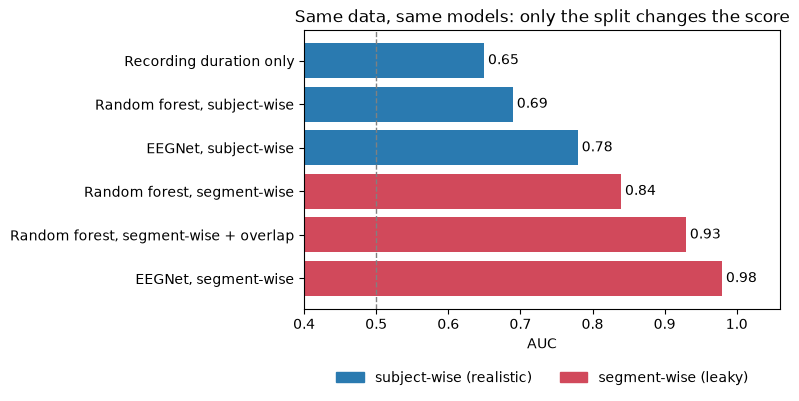

In [2]:
import matplotlib.pyplot as plt
import os

rungs = [  # (label, AUC, subject-wise?)
    ("Recording duration only",               0.65, True),
    ("Random forest, subject-wise",           0.69, True),
    ("EEGNet, subject-wise",                  0.78, True),
    ("Random forest, segment-wise",           0.84, False),
    ("Random forest, segment-wise + overlap", 0.93, False),
    ("EEGNet, segment-wise",                  0.98, False),
]
labels, aucs, honest = zip(*rungs)
colors = ["#2a7ab0" if h else "#d1495b" for h in honest]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(labels, aucs, color=colors)
ax.axvline(0.5, color="grey", ls="--", lw=1)
for i, a in enumerate(aucs):
    ax.text(a + 0.005, i, f"{a:.2f}", va="center")
ax.set_xlim(0.4, 1.06)
ax.set_xlabel("AUC")
ax.set_title("Same data, same models: only the split changes the score")
ax.invert_yaxis()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#2a7ab0"), plt.Rectangle((0, 0), 1, 1, color="#d1495b")],
          labels=["subject-wise (realistic)", "segment-wise (leaky)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/leakage_ladder.png", dpi=200, bbox_inches="tight")
plt.show()